# Phase 4: Random Forest — how early can dropout be predicted?

**Guiding question:** *how early can we predict who will drop out, and how much does the prediction improve as more information becomes available?*

We predict `Target` (Dropout / Enrolled / Graduate) in **four scenarios**, according to *when* the prediction is made:

| Scenario | Information available | Why |
|---|---|---|
| **1a. At enrolment (no economic)** | demographics, admission grades, application mode/order, course, parents' education | what the university knows on day 1 |
| **1b. At enrolment (+ economic)** | 1a + `Debtor`, `Tuition_Up_To_Date`, `Scholarship_Holder` | these may be recorded *after* enrolment, so they can partly be a consequence of dropout |
| **2. After the 1st semester** | 1b + 1st-semester performance | first warning signs |
| **3. After the 2nd semester** | 2 + 2nd-semester performance | end of the first year |

Performance variables are **excluded** from the scenarios in which they do not exist yet, otherwise the model would "cheat".

**Method (as in the project plan):** stratified 80/20 train/test split + stratified 5-fold CV on the training set, `class_weight="balanced"`, two baselines (majority class and logistic regression), **F1 macro** as main metric (accuracy alone is misleading with unbalanced classes), confusion matrices, permutation importance.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, precision_score, recall_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# ---- common project style (same cell as the other notebooks) ----
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 5), "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
})
OUTCOME_ORDER = ["Dropout", "Enrolled", "Graduate"]
OUTCOME_PALETTE = {"Dropout": "#9b4141", "Enrolled": "#b8b8b8", "Graduate": "#298c8c"}
BAR_COLOR = "#0072B2"
DROPOUT_COLOR = "#9b4141"
# model colours (colour-blind safe): baseline grey, logistic regression light blue, random forest blue
MODEL_PALETTE = {"Majority class": "#b8b8b8", "Logistic regression": "#56B4E9", "Random Forest": "#0072B2"}

ORDER = {
    "Target": OUTCOME_ORDER, "Gender": ["Female", "Male"], "Displaced": ["No", "Yes"],
    "Debtor": ["No", "Yes"], "Tuition_Up_To_Date": ["No", "Yes"], "Scholarship_Holder": ["No", "Yes"],
    "Daytime_Evening": ["Daytime", "Evening"], "Marital_Group": ["Single", "Not single"],
    "Age_Group": ["17-19", "20-24", "25-29", "30+"],
    "Admission_Grade_Band": ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"],
    "Parent_Education": ["Basic", "Secondary", "Higher", "Unknown"],
    "Application_Order_Group": ["0-1", "2", "3+"],
    "Application_Mode_Group": ["General contingent", "Over 23 years old", "Transfer or change",
                               "Prior diploma holder", "Special or other"],
    "Passed_None_1st": ["No", "Yes"], "Passed_None_2nd": ["No", "Yes"],
}
def apply_order(df):
    df = df.copy()
    for col, cats in ORDER.items():
        if col in df.columns:
            df[col] = pd.Categorical(df[col], categories=cats, ordered=True)
    return df

# ---- paths (works in the repo, or in Colab with the csv in the working folder) ----
CANDIDATES = ["student_dropout_cleaned.csv", "data/processed/student_dropout_cleaned.csv",
              "../data/processed/student_dropout_cleaned.csv"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
FIG_DIR, RES_DIR = "figures/phase4_RF", "results"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)
print("Data:", DATA_PATH)

Data: data/processed/student_dropout_cleaned.csv


## 1. Data and missing values

We use the clean file from Phase 0. As decided in the cleaning documentation, for the models:
- `Grade_1st` / `Grade_2nd` missing → **0** (the original value: *no unit passed*);
- `Approval_Rate_1st` / `Approval_Rate_2nd` missing → **0** for the 180 students enrolled in 0 units;
- the information "no unit passed" is kept through `Enrolled_*` and `Approved_*` (together they say exactly when a student enrolled in units but passed none), so we do not add `Passed_None_*` (it would be redundant, and its missing values would be ambiguous).

In [2]:
data = apply_order(pd.read_csv(DATA_PATH))
model_df = data.copy()

for c in ["Grade_1st", "Grade_2nd", "Approval_Rate_1st", "Approval_Rate_2nd"]:
    model_df[c] = model_df[c].fillna(0)

# categorical columns -> plain strings for scikit-learn
CAT_COLS = ["Marital_Group", "Application_Mode_Group", "Course_Name", "Parent_Education",
            "Daytime_Evening", "Gender", "Displaced", "Debtor", "Tuition_Up_To_Date", "Scholarship_Holder"]
for c in CAT_COLS:
    model_df[c] = model_df[c].astype(str)

y = model_df["Target"].astype(str)
print(model_df.shape)
print(y.value_counts().to_string())
print("\nClass shares (%):"); print((y.value_counts(normalize=True) * 100).round(1).to_string())

(4424, 41)
Target
Graduate    2209
Dropout     1421
Enrolled     794

Class shares (%):
Target
Graduate    49.9
Dropout     32.1
Enrolled    17.9


## 2. The four scenarios (feature sets)

Everything is built **cumulatively**: each scenario contains the previous one plus new information.
`Course_Name` and `Daytime_Evening` are strongly linked (two evening courses), so both stay in the model and are read together.

In [3]:
DEMOGRAPHICS = ["Gender", "Age_At_Enrollment", "Marital_Group", "Displaced"]
ADMISSION    = ["Admission_Grade", "Prev_Qual_Grade", "Application_Mode_Group", "Application_Order"]
COURSE       = ["Course_Name", "Daytime_Evening"]
PARENTS      = ["Parent_Education"]
ECONOMIC     = ["Debtor", "Tuition_Up_To_Date", "Scholarship_Holder"]
PERF_1ST     = ["Enrolled_1st", "Approved_1st", "Grade_1st", "Approval_Rate_1st"]
PERF_2ND     = ["Enrolled_2nd", "Approved_2nd", "Grade_2nd", "Approval_Rate_2nd"]

# optional: add the cluster label from Phase 3 (Person 2), e.g.
# model_df["Cluster"] = pd.read_csv("student_clusters.csv")["Cluster"].astype(str); EXTRA = ["Cluster"]
EXTRA = []

FEATURE_BLOCKS = {
    "1a. At enrolment (no economic)": DEMOGRAPHICS + ADMISSION + COURSE + PARENTS + EXTRA,
    "1b. At enrolment (+ economic)":  DEMOGRAPHICS + ADMISSION + COURSE + PARENTS + EXTRA + ECONOMIC,
    "2. After 1st semester":          DEMOGRAPHICS + ADMISSION + COURSE + PARENTS + EXTRA + ECONOMIC + PERF_1ST,
    "3. After 2nd semester":          DEMOGRAPHICS + ADMISSION + COURSE + PARENTS + EXTRA + ECONOMIC + PERF_1ST + PERF_2ND,
}
SCENARIOS = list(FEATURE_BLOCKS)
SHORT = {s: s.split(".")[0] for s in SCENARIOS}
SCEN_LABEL = {"1a": "1a\nEnrolment\n(no economic)", "1b": "1b\nEnrolment\n(+ economic)",
              "2": "2\nAfter 1st\nsemester", "3": "3\nAfter 2nd\nsemester"}

def split_cols(cols):
    cats = [c for c in cols if c in CAT_COLS or c in EXTRA]
    nums = [c for c in cols if c not in cats]
    return cats, nums

pd.DataFrame({"scenario": SCENARIOS,
              "n_features": [len(v) for v in FEATURE_BLOCKS.values()],
              "added vs previous": ["-", "+ 3 economic", "+ 4 (1st semester)", "+ 4 (2nd semester)"]})

,scenario,n_features,added vs previous
0,1a. At enrolment (no economic),11,-
1,1b. At enrolment (+ economic),14,+ 3 economic
2,2. After 1st semester,18,+ 4 (1st semester)
3,3. After 2nd semester,22,+ 4 (2nd semester)


## 3. Train/test split and cross-validation

80/20 **stratified** split (same split for all scenarios, so results are comparable) and stratified 5-fold CV **inside the training set** for model selection. The test set is used only once, at the end.

In [4]:
idx_train, idx_test = train_test_split(model_df.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {len(idx_train)}  |  Test: {len(idx_test)}")
print(pd.DataFrame({"train %": y_train.value_counts(normalize=True) * 100,
                    "test %": y_test.value_counts(normalize=True) * 100}).round(1).loc[OUTCOME_ORDER])

Train: 3539  |  Test: 885
          train %  test %
Target                   
Dropout      32.1    32.1
Enrolled     17.9    18.0
Graduate     49.9    49.9


## 4. Models

- **Baseline 1:** always predict the most frequent class (*Graduate*).
- **Baseline 2:** multinomial **logistic regression** (`class_weight="balanced"`, standardised numerics).
- **Random Forest** (`class_weight="balanced"`, 500 trees). Few hyper-parameters (`min_samples_leaf`, `max_features`) are chosen with a small grid search maximising **F1 macro** in the 5-fold CV of the training set.

One-hot encoding for categorical variables is inside the pipeline, so it is fitted only on training folds (no leakage).

In [5]:
def make_pipe(cats, nums, model, scale=False):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
        ("num", StandardScaler() if scale else "passthrough", nums),
    ])
    return Pipeline([("prep", pre), ("model", model)])

def rf_model(n_estimators=500, **kw):
    return RandomForestClassifier(n_estimators=n_estimators, class_weight="balanced",
                                  random_state=RANDOM_STATE, n_jobs=-1, **kw)

PARAM_GRID = {"model__min_samples_leaf": [1, 3, 5, 10], "model__max_features": ["sqrt", 0.3]}

def cv_f1(pipe, Xtr):
    from sklearn.model_selection import cross_val_score
    s = cross_val_score(pipe, Xtr, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    return s.mean(), s.std()

results, fitted, preds = [], {}, {}
for name in SCENARIOS:
    cols = FEATURE_BLOCKS[name]; cats, nums = split_cols(cols)
    Xtr, Xte = model_df.loc[idx_train, cols], model_df.loc[idx_test, cols]

    # baseline 1: majority class
    dummy = make_pipe(cats, nums, DummyClassifier(strategy="most_frequent")).fit(Xtr, y_train)
    # baseline 2: logistic regression
    lr = make_pipe(cats, nums, LogisticRegression(max_iter=3000, class_weight="balanced"), scale=True)
    lr_cv = cv_f1(lr, Xtr); lr.fit(Xtr, y_train)
    # random forest: small grid search (F1 macro, stratified 5-fold CV on train)
    gs = GridSearchCV(make_pipe(cats, nums, rf_model(n_estimators=200)), PARAM_GRID,
                      scoring="f1_macro", cv=cv, n_jobs=1, refit=False).fit(Xtr, y_train)
    best = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
    rf = make_pipe(cats, nums, rf_model(**best)).fit(Xtr, y_train)
    b = gs.best_index_
    rf_cv = (gs.cv_results_["mean_test_score"][b], gs.cv_results_["std_test_score"][b])

    fitted[name] = {"Majority class": dummy, "Logistic regression": lr, "Random Forest": rf, "best": best}
    for mname, mod, cvres in [("Majority class", dummy, (np.nan, np.nan)),
                              ("Logistic regression", lr, lr_cv), ("Random Forest", rf, rf_cv)]:
        p = mod.predict(Xte); preds[(name, mname)] = p
        results.append({"scenario": name, "model": mname,
                        "cv_f1_macro": cvres[0], "cv_f1_std": cvres[1],
                        "test_accuracy": accuracy_score(y_test, p),
                        "test_f1_macro": f1_score(y_test, p, average="macro")})
    print(f"{name:34s} best RF params: {best}")

res = pd.DataFrame(results)
res.round(3)

1a. At enrolment (no economic)     best RF params: {'max_features': 'sqrt', 'min_samples_leaf': 10}


1b. At enrolment (+ economic)      best RF params: {'max_features': 'sqrt', 'min_samples_leaf': 5}


2. After 1st semester              best RF params: {'max_features': 'sqrt', 'min_samples_leaf': 5}


3. After 2nd semester              best RF params: {'max_features': 'sqrt', 'min_samples_leaf': 1}


,scenario,model,cv_f1_macro,cv_f1_std,test_accuracy,test_f1_macro
0,1a. At enrolment (no economic),Majority class,NaN,NaN,0.499,0.222
1,1a. At enrolment (no economic),Logistic regression,0.499,0.019,0.537,0.490
2,1a. At enrolment (no economic),Random Forest,0.514,0.019,0.518,0.476
3,1b. At enrolment (+ economic),Majority class,NaN,NaN,0.499,0.222
4,1b. At enrolment (+ economic),Logistic regression,0.551,0.011,0.559,0.533
5,1b. At enrolment (+ economic),Random Forest,0.559,0.018,0.568,0.536
6,2. After 1st semester,Majority class,NaN,NaN,0.499,0.222
7,2. After 1st semester,Logistic regression,0.671,0.016,0.693,0.654
8,2. After 1st semester,Random Forest,0.687,0.022,0.711,0.666
9,3. After 2nd semester,Majority class,NaN,NaN,0.499,0.222


### 4.1 Does the Random Forest add value over the baselines?

Main figure of the phase: **F1 macro on the test set**, per scenario and model (accuracy on the left for reference).

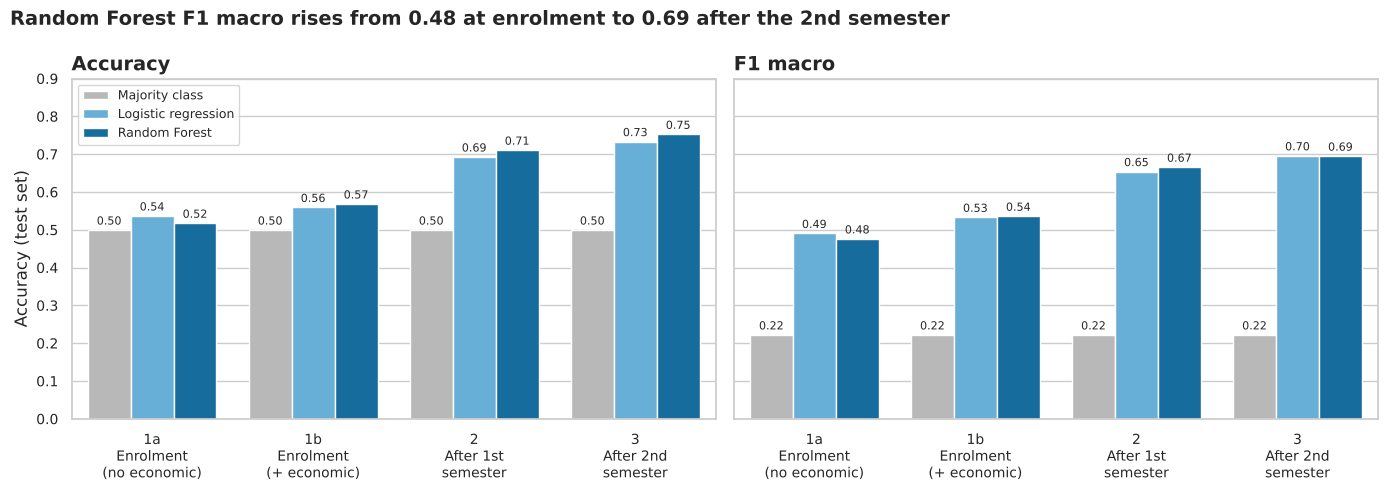

Cross-validation F1 macro on the training set (mean ± std over 5 folds):


model,Logistic regression,Random Forest
scenario,,
1a. At enrolment (no economic),0.499 ± 0.019,0.514 ± 0.019
1b. At enrolment (+ economic),0.551 ± 0.011,0.559 ± 0.018
2. After 1st semester,0.671 ± 0.016,0.687 ± 0.022
3. After 2nd semester,0.708 ± 0.015,0.72 ± 0.015


In [6]:
res["sc"] = res["scenario"].map(SHORT)
rf_t = res[res.model == "Random Forest"].set_index("sc")
f1_first, f1_last = rf_t.loc["1a", "test_f1_macro"], rf_t.loc["3", "test_f1_macro"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, metric, ttl in zip(axes, ["test_accuracy", "test_f1_macro"], ["Accuracy", "F1 macro"]):
    sns.barplot(data=res, x="sc", y=metric, hue="model", hue_order=list(MODEL_PALETTE),
                palette=MODEL_PALETTE, order=["1a", "1b", "2", "3"], ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticklabels([SCEN_LABEL[t.get_text()] for t in ax.get_xticklabels()])
    ax.set_xlabel(""); ax.set_ylabel(ttl + " (test set)"); ax.set_ylim(0, 0.9); ax.set_title(ttl, loc="left")
    ax.legend(title="", loc="upper left", fontsize=9) if metric == "test_accuracy" else ax.get_legend().remove()
fig.suptitle(f"Random Forest F1 macro rises from {f1_first:.2f} at enrolment to {f1_last:.2f} after the 2nd semester",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/F1_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

print("Cross-validation F1 macro on the training set (mean ± std over 5 folds):")
cv_tab = res.pivot(index="scenario", columns="model", values="cv_f1_macro").round(3).astype(str) + " ± " + \
         res.pivot(index="scenario", columns="model", values="cv_f1_std").round(3).astype(str)
cv_tab.drop(columns="Majority class").loc[SCENARIOS]

### 4.2 Precision and recall by class

A single number hides what happens to each class. `Enrolled` is expected to be the hardest class: these students have not finished yet, so they sit "between" Dropout and Graduate.

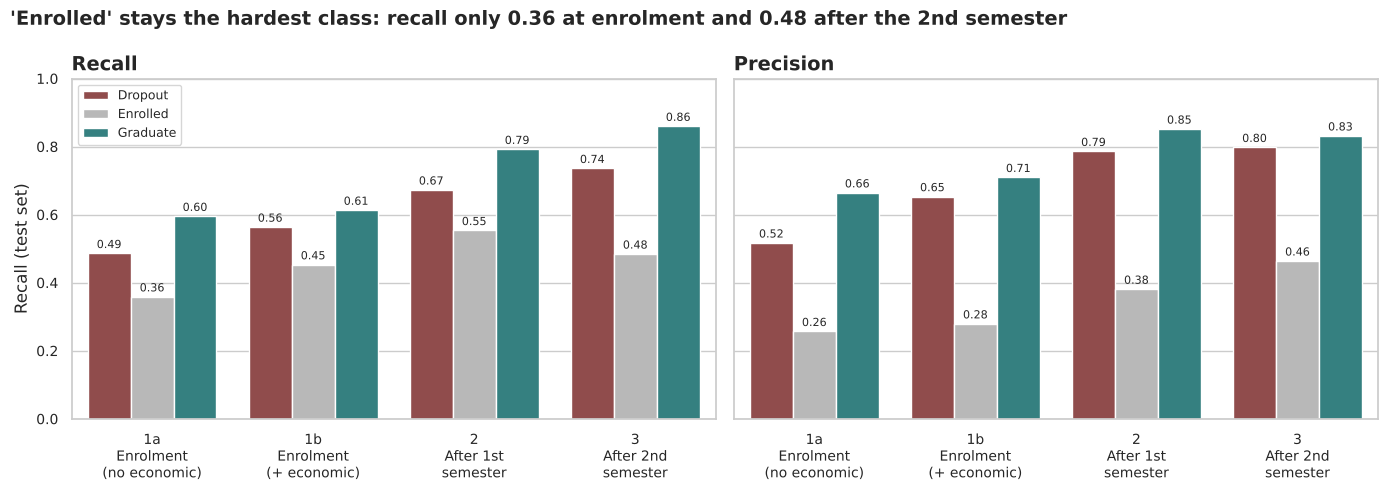

,scenario,class,precision,recall,f1,support
0,1a. At enrolment (no economic),Dropout,0.517,0.486,0.501,284
1,1a. At enrolment (no economic),Enrolled,0.257,0.358,0.299,159
2,1a. At enrolment (no economic),Graduate,0.664,0.595,0.628,442
3,1b. At enrolment (+ economic),Dropout,0.653,0.563,0.605,284
4,1b. At enrolment (+ economic),Enrolled,0.279,0.453,0.345,159
5,1b. At enrolment (+ economic),Graduate,0.709,0.613,0.658,442
6,2. After 1st semester,Dropout,0.786,0.673,0.725,284
7,2. After 1st semester,Enrolled,0.381,0.553,0.451,159
8,2. After 1st semester,Graduate,0.852,0.792,0.821,442
9,3. After 2nd semester,Dropout,0.798,0.736,0.766,284


In [7]:
rows = []
for name in SCENARIOS:
    rep = classification_report(y_test, preds[(name, "Random Forest")], labels=OUTCOME_ORDER, output_dict=True, zero_division=0)
    for cl in OUTCOME_ORDER:
        rows.append({"scenario": name, "sc": SHORT[name], "class": cl, "precision": rep[cl]["precision"],
                     "recall": rep[cl]["recall"], "f1": rep[cl]["f1-score"], "support": int(rep[cl]["support"])})
pc = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, metric in zip(axes, ["recall", "precision"]):
    sns.barplot(data=pc, x="sc", y=metric, hue="class", hue_order=OUTCOME_ORDER, palette=OUTCOME_PALETTE,
                order=["1a", "1b", "2", "3"], ax=ax)
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticklabels([SCEN_LABEL[t.get_text()] for t in ax.get_xticklabels()])
    ax.set_xlabel(""); ax.set_ylim(0, 1.0); ax.set_ylabel(metric.capitalize() + " (test set)")
    ax.set_title(metric.capitalize(), loc="left")
    ax.legend(title="", loc="upper left", fontsize=9) if metric == "recall" else ax.get_legend().remove()
enr_rec = pc[(pc["class"] == "Enrolled")].set_index("sc")["recall"]
fig.suptitle(f"'Enrolled' stays the hardest class: recall only {enr_rec['1a']:.2f} at enrolment and {enr_rec['3']:.2f} after the 2nd semester",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/F2_precision_recall_by_class.png", dpi=200, bbox_inches="tight"); plt.show()

pc.drop(columns="sc").round(3)

### 4.3 Confusion matrices

Rows = true class, columns = predicted class. Each row is normalised (percentage of that class), with absolute counts in brackets.

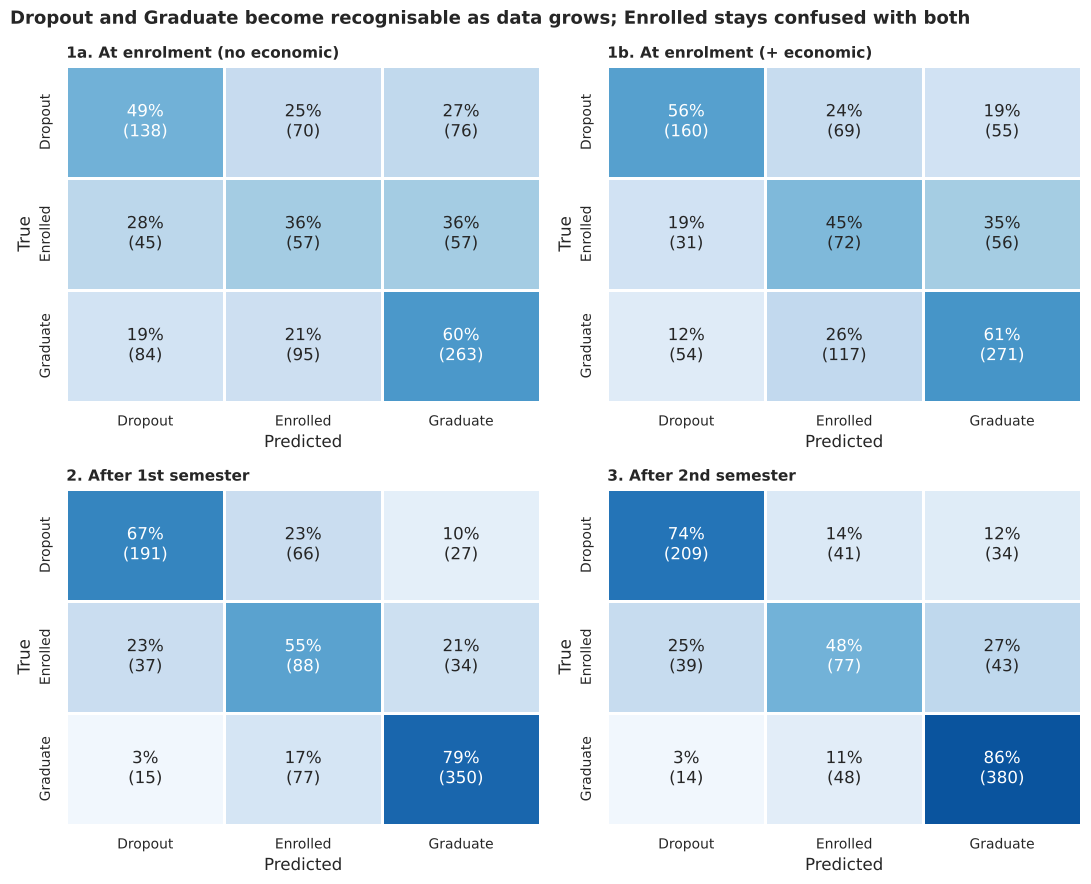

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.ravel(), SCENARIOS):
    cm = confusion_matrix(y_test, preds[(name, "Random Forest")], labels=OUTCOME_ORDER)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cmn[i, j]*100:.0f}%\n({cm[i, j]})" for j in range(3)] for i in range(3)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=OUTCOME_ORDER, yticklabels=OUTCOME_ORDER, linewidths=1, linecolor="white")
    ax.set_title(name, fontsize=11, loc="left"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
fig.suptitle("Dropout and Graduate become recognisable as data grows; Enrolled stays confused with both",
             fontsize=13, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/F3_confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. What drives the predictions? Permutation importance

Impurity-based importances of a Random Forest are biased towards numeric/high-cardinality variables, so we use **permutation importance on the test set**: how much F1 macro drops when a variable is randomly shuffled (10 repetitions).

Many variables are strongly correlated (e.g. `Enrolled_1st`, `Approved_1st`, `Approval_Rate_1st`): shuffling one of them alone underestimates the importance of the whole block, because the others still carry the information. We therefore compute importance **twice**:
1. **by block** (shuffle all variables of a block together), which answers *"which kind of information matters?"*;
2. **by single variable**, which answers *"which variable inside the block?"*.

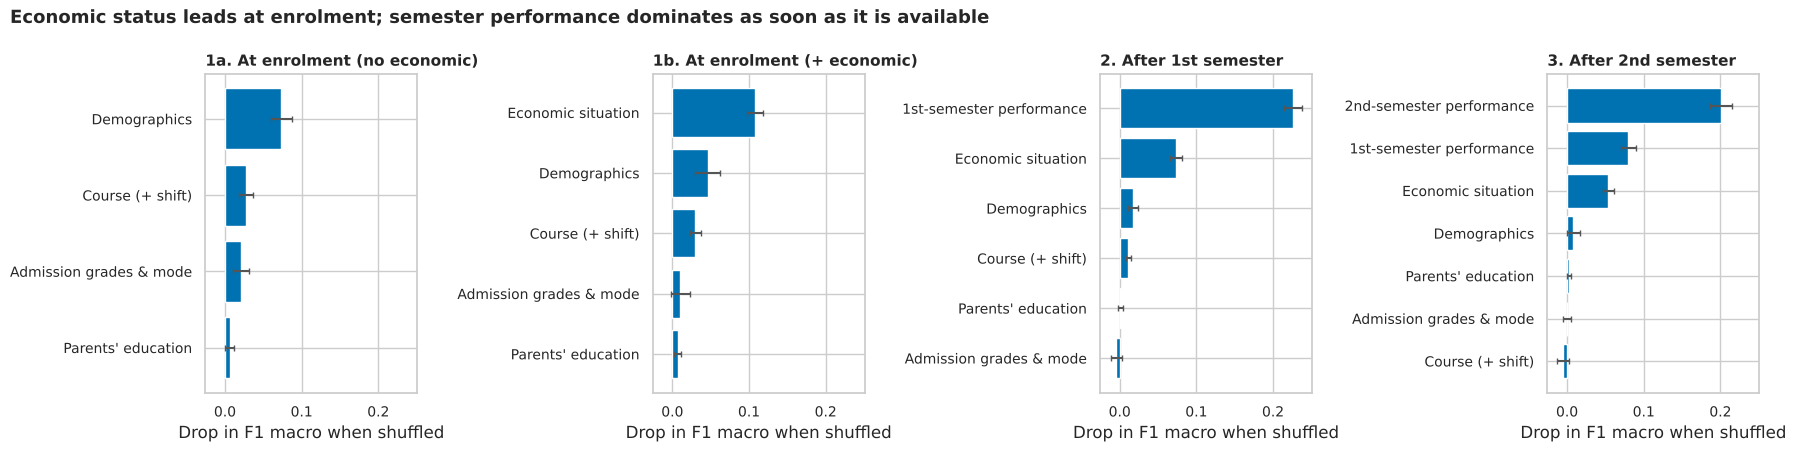

,1a,1b,2,3
Demographics,0.074,0.046,0.017,0.008
Admission grades & mode,0.021,0.01,-0.004,0.000
Course (+ shift),0.028,0.03,0.011,-0.005
Parents' education,0.006,0.007,0.001,0.003
Economic situation,-,0.107,0.073,0.054
1st-semester performance,-,-,0.226,0.080
2nd-semester performance,-,-,-,0.200


In [9]:
BLOCKS = {"Demographics": DEMOGRAPHICS, "Admission grades & mode": ADMISSION, "Course (+ shift)": COURSE,
          "Parents' education": PARENTS, "Economic situation": ECONOMIC,
          "1st-semester performance": PERF_1ST, "2nd-semester performance": PERF_2ND}

def block_importance(pipe, Xte, yte, blocks, n_repeats=10, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = f1_score(yte, pipe.predict(Xte), average="macro")
    out = {}
    for bname, cols in blocks.items():
        cols = [c for c in cols if c in Xte.columns]
        if not cols: continue
        drops = []
        for _ in range(n_repeats):
            Xp = Xte.copy(); perm = rng.permutation(len(Xp))
            Xp[cols] = Xte[cols].values[perm]          # same permutation for the whole block
            drops.append(base - f1_score(yte, pipe.predict(Xp), average="macro"))
        out[bname] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=["drop", "std"]).T

block_imp, var_imp = {}, {}
for name in SCENARIOS:
    cols = FEATURE_BLOCKS[name]; rf = fitted[name]["Random Forest"]; Xte = model_df.loc[idx_test, cols]
    block_imp[name] = block_importance(rf, Xte, y_test, BLOCKS)
    pi = permutation_importance(rf, Xte, y_test, scoring="f1_macro", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
    var_imp[name] = pd.DataFrame({"drop": pi.importances_mean, "std": pi.importances_std}, index=cols).sort_values("drop", ascending=False)

# ---- figure: importance by block, one panel per scenario, same x scale ----
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), sharex=True)
for ax, name in zip(axes, SCENARIOS):
    d = block_imp[name].sort_values("drop")
    ax.barh(d.index, d["drop"], xerr=d["std"], color=BAR_COLOR, ecolor="#555555", capsize=2)
    ax.set_title(name, fontsize=11, loc="left"); ax.set_xlabel("Drop in F1 macro when shuffled")
axes[0].set_ylabel("")
fig.suptitle("Economic status leads at enrolment; semester performance dominates as soon as it is available",
             fontsize=13, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/F4_block_importance.png", dpi=200, bbox_inches="tight"); plt.show()

pd.concat({SHORT[k]: v["drop"].round(3) for k, v in block_imp.items()}, axis=1).fillna("-")

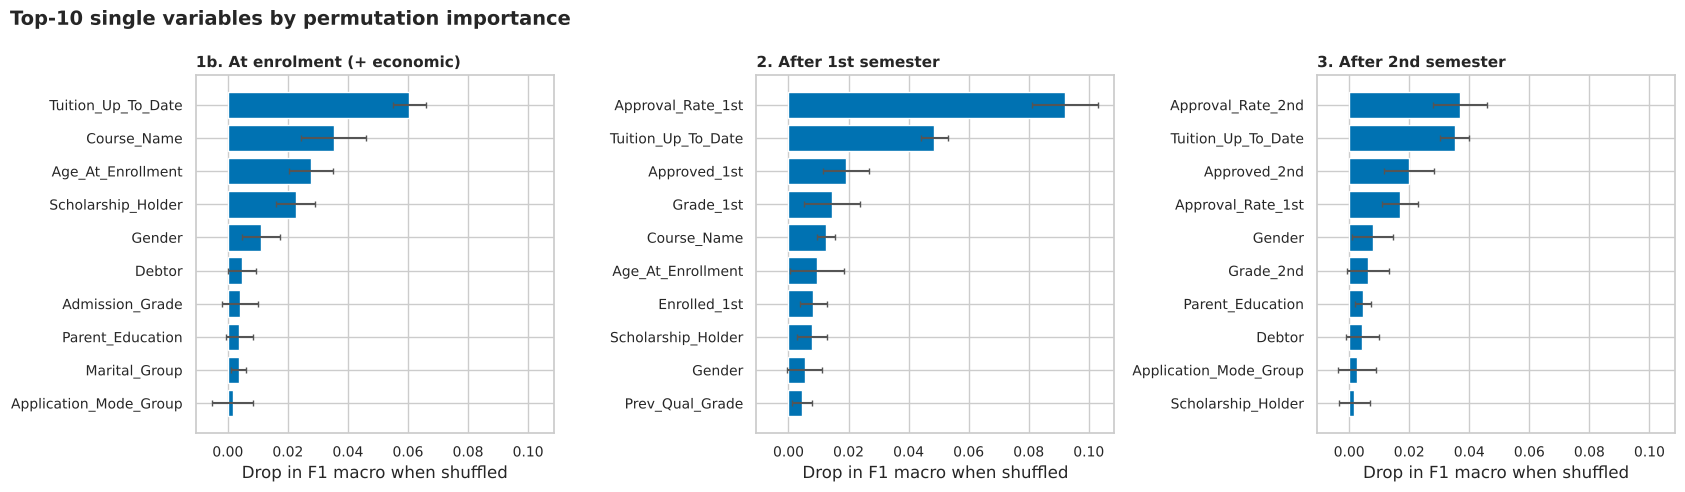

Top-5 single variables per scenario:


,1a,1b,2,3
1,Age_At_Enrollment (0.053),Tuition_Up_To_Date (0.060),Approval_Rate_1st (0.092),Approval_Rate_2nd (0.037)
2,Course_Name (0.028),Course_Name (0.035),Tuition_Up_To_Date (0.049),Tuition_Up_To_Date (0.035)
3,Application_Mode_Group (0.010),Age_At_Enrollment (0.028),Approved_1st (0.019),Approved_2nd (0.020)
4,Admission_Grade (0.008),Scholarship_Holder (0.023),Grade_1st (0.015),Approval_Rate_1st (0.017)
5,Gender (0.006),Gender (0.011),Course_Name (0.013),Gender (0.008)


In [10]:
# ---- figure: top-10 single variables for scenarios 1b, 2, 3 ----
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
for ax, name in zip(axes, SCENARIOS[1:]):
    d = var_imp[name].head(10).iloc[::-1]
    ax.barh(d.index, d["drop"], xerr=d["std"], color=BAR_COLOR, ecolor="#555555", capsize=2)
    ax.set_title(name, fontsize=11, loc="left"); ax.set_xlabel("Drop in F1 macro when shuffled")
fig.suptitle("Top-10 single variables by permutation importance", fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/F5_top_variables.png", dpi=200, bbox_inches="tight"); plt.show()

print("Top-5 single variables per scenario:")
pd.DataFrame({SHORT[k]: [f"{i} ({v:.3f})" for i, v in zip(d.index[:5], d['drop'][:5])] for k, d in var_imp.items()}, index=range(1, 6))

**Comparison with the impurity-based (MDI) importance** of the same forest, summed by original variable (one-hot columns of the same variable are added up). It is a sanity check: if the rankings are very different, be careful when interpreting.

In [11]:
def mdi_by_variable(pipe, cats, nums):
    names = pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
    agg = {}
    for n, v in imp.items():
        base = n.split("__", 1)[1]
        orig = next((c for c in cats if base.startswith(c + "_")), base)
        agg[orig] = agg.get(orig, 0) + v
    return pd.Series(agg).sort_values(ascending=False)

mdi = {}
for name in SCENARIOS:
    cats, nums = split_cols(FEATURE_BLOCKS[name])
    mdi[name] = mdi_by_variable(fitted[name]["Random Forest"], cats, nums)
pd.DataFrame({SHORT[k]: [f"{i} ({v:.2f})" for i, v in zip(s.index[:5], s[:5])] for k, s in mdi.items()}, index=range(1, 6))

,1a,1b,2,3
1,Course_Name (0.21),Tuition_Up_To_Date (0.19),Approval_Rate_1st (0.19),Approval_Rate_2nd (0.11)
2,Age_At_Enrollment (0.18),Course_Name (0.14),Approved_1st (0.14),Grade_2nd (0.09)
3,Admission_Grade (0.13),Age_At_Enrollment (0.11),Grade_1st (0.13),Approved_2nd (0.08)
4,Prev_Qual_Grade (0.12),Admission_Grade (0.10),Tuition_Up_To_Date (0.10),Course_Name (0.07)
5,Application_Mode_Group (0.11),Scholarship_Holder (0.09),Course_Name (0.06),Approval_Rate_1st (0.07)


## 6. Optional: binary version (Dropout vs everything else)

`Enrolled` is an ambiguous class (not a final outcome). The binary question *"will this student drop out?"* is closer to a real early-warning use. Same scenarios, same split, same hyper-parameters found above; `Dropout` is the positive class.

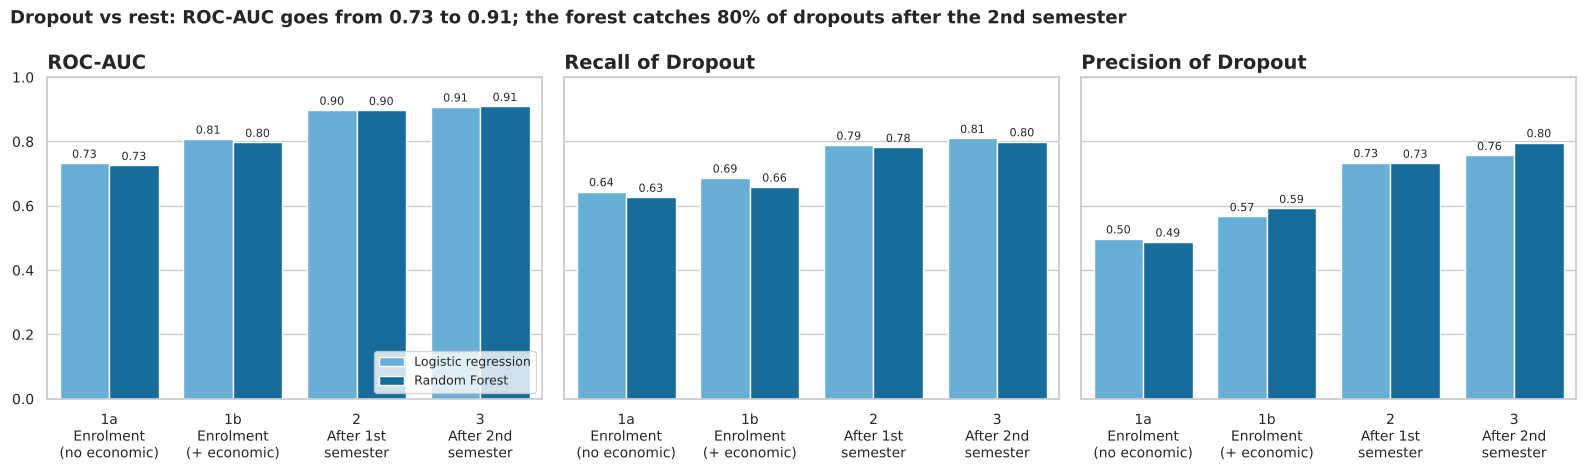

,scenario,model,roc_auc,dropout_recall,dropout_precision,dropout_f1,accuracy
0,1a. At enrolment (no economic),Random Forest,0.726,0.627,0.488,0.549,0.669
1,1a. At enrolment (no economic),Logistic regression,0.732,0.644,0.497,0.561,0.677
2,1b. At enrolment (+ economic),Random Forest,0.797,0.658,0.592,0.623,0.745
3,1b. At enrolment (+ economic),Logistic regression,0.807,0.687,0.567,0.621,0.731
4,2. After 1st semester,Random Forest,0.897,0.782,0.733,0.756,0.838
5,2. After 1st semester,Logistic regression,0.898,0.789,0.734,0.761,0.841
6,3. After 2nd semester,Random Forest,0.909,0.799,0.796,0.798,0.870
7,3. After 2nd semester,Logistic regression,0.907,0.810,0.757,0.782,0.855


In [12]:
yb_train, yb_test = (y_train == "Dropout").astype(int), (y_test == "Dropout").astype(int)
bin_rows, bin_pred = [], {}
for name in SCENARIOS:
    cols = FEATURE_BLOCKS[name]; cats, nums = split_cols(cols)
    Xtr, Xte = model_df.loc[idx_train, cols], model_df.loc[idx_test, cols]
    rfb = make_pipe(cats, nums, rf_model(**fitted[name]["best"])).fit(Xtr, yb_train)
    proba = rfb.predict_proba(Xte)[:, 1]; p = (proba >= 0.5).astype(int)
    lrb = make_pipe(cats, nums, LogisticRegression(max_iter=3000, class_weight="balanced"), scale=True).fit(Xtr, yb_train)
    for mname, pp, pr in [("Random Forest", p, proba), ("Logistic regression", lrb.predict(Xte), lrb.predict_proba(Xte)[:, 1])]:
        bin_rows.append({"scenario": name, "sc": SHORT[name], "model": mname,
                         "roc_auc": roc_auc_score(yb_test, pr), "dropout_recall": recall_score(yb_test, pp),
                         "dropout_precision": precision_score(yb_test, pp), "dropout_f1": f1_score(yb_test, pp),
                         "accuracy": accuracy_score(yb_test, pp)})
    bin_pred[name] = rfb
binr = pd.DataFrame(bin_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, metric, ttl in zip(axes, ["roc_auc", "dropout_recall", "dropout_precision"],
                           ["ROC-AUC", "Recall of Dropout", "Precision of Dropout"]):
    sns.barplot(data=binr, x="sc", y=metric, hue="model", hue_order=["Logistic regression", "Random Forest"],
                palette=MODEL_PALETTE, order=["1a", "1b", "2", "3"], ax=ax)
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticklabels([SCEN_LABEL[t.get_text()] for t in ax.get_xticklabels()])
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_ylim(0, 1.0); ax.set_title(ttl, loc="left")
    ax.legend(title="", loc="lower right", fontsize=9) if metric == "roc_auc" else ax.get_legend().remove()
auc = binr[binr.model == "Random Forest"].set_index("sc")["roc_auc"]
rec = binr[binr.model == "Random Forest"].set_index("sc")["dropout_recall"]
fig.suptitle(f"Dropout vs rest: ROC-AUC goes from {auc['1a']:.2f} to {auc['3']:.2f}; the forest catches {rec['3']*100:.0f}% of dropouts after the 2nd semester",
             fontsize=13, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/F6_binary_dropout.png", dpi=200, bbox_inches="tight"); plt.show()
binr.drop(columns="sc").round(3)

In [13]:
# ---- save all tables ----
res.drop(columns="sc").round(4).to_csv(f"{RES_DIR}/phase4_multiclass_metrics.csv", index=False)
pc.drop(columns="sc").round(4).to_csv(f"{RES_DIR}/phase4_per_class_metrics_RF.csv", index=False)
binr.drop(columns="sc").round(4).to_csv(f"{RES_DIR}/phase4_binary_metrics.csv", index=False)
pd.concat({SHORT[k]: v for k, v in block_imp.items()}).round(4).to_csv(f"{RES_DIR}/phase4_block_importance.csv")
pd.concat({SHORT[k]: v for k, v in var_imp.items()}).round(4).to_csv(f"{RES_DIR}/phase4_variable_importance.csv")
print(sorted(os.listdir(FIG_DIR))); print(sorted(os.listdir(RES_DIR)))

['F1_model_comparison.png', 'F2_precision_recall_by_class.png', 'F3_confusion_matrices.png', 'F4_block_importance.png', 'F5_top_variables.png', 'F6_binary_dropout.png']
['phase4_binary_metrics.csv', 'phase4_block_importance.csv', 'phase4_multiclass_metrics.csv', 'phase4_per_class_metrics_RF.csv', 'phase4_variable_importance.csv']


## 7. Key messages and limits

**Key messages**
1. **The earlier, the harder.** Random Forest F1 macro: **0.48** at enrolment, **0.54** with economic variables, **0.67** after the 1st semester, **0.69** after the 2nd (majority-class baseline: 0.22). Accuracy goes 0.52 → 0.57 → 0.71 → 0.75 (baseline 0.50).
2. **The 1st semester is the turning point:** +0.13 F1 macro, while the 2nd semester adds only +0.03. The first warning signs are already visible after 6 months.
3. **Economic variables help at enrolment (+0.06 F1 macro)**, mainly `Tuition_Up_To_Date`, but they may be partly a *consequence* of dropping out (see caveat), so scenario 1a is the "clean" early prediction.
4. **Random Forest does not clearly beat logistic regression** (differences ≤ 0.02, similar to the CV standard deviation of ≈ 0.02). Most of the signal is simple and almost linear.
5. **`Enrolled` is the hardest class** (F1 from 0.30 to 0.47): it is not a final outcome, so it overlaps with both Dropout and Graduate.
6. **Dropout vs rest** is easier: ROC-AUC 0.73 → 0.91; after the 1st semester the forest catches 78% of dropouts with 73% precision.
7. **What matters:** age and course at enrolment; tuition fees up to date when available; the 1st-semester approval rate (the single most important variable after semester 1). This agrees with Blocks A, B and D.

**Limits**
- One 20% test set (885 students): differences of ~0.02-0.03 are within noise.
- Performance variables are a *consequence* as much as a predictor; `Tuition_Up_To_Date` may be recorded after the student leaves.
- One Portuguese institution; unbalanced classes; `Enrolled` is ambiguous.
- Prediction is not causation, and permutation importance splits credit between correlated variables.
- **Ethics:** `Gender` and `Age_At_Enrollment` are in the model. An early-warning system must be used to **offer support**, never to exclude students.